# Metric Stat Analysis – PPP Radar Evaluation

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by
the metric evaluation pipeline and provides first-look visualisation of
`img`, `pred_lambda`, and `gt_support` per sample.

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32
```

## 1 · Import Required Libraries

In [1]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [2]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

# Select which model to analyse for the browser / per-sample cells
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files for the active model (browser / per-sample cells)
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nAll models registered: {list(H5_DIRS.keys())}")
print(f"GT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

All models registered: ['test_gen_data_meric_13600264', 'test_gen_data_meric_1500_13603608']
GT_DILATION_RADIUS = 1  (display only)


## 3 · H5 Helper – List & Load Samples

In [3]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [4]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792) _gt_support=(544, 1792)
PPP    : E[N]=106.85  GT=67  err=+39.85


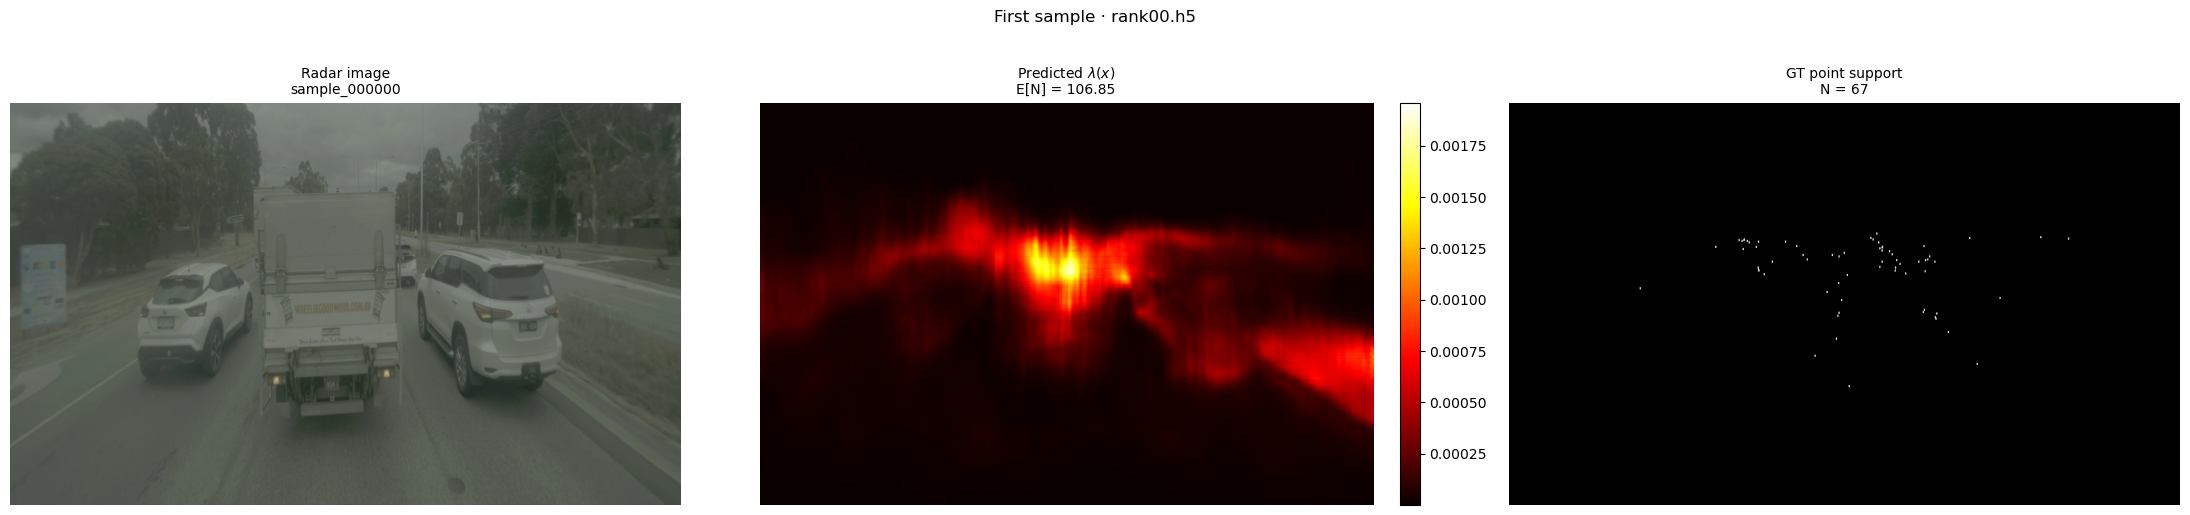

In [5]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape} _gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

In [6]:
# Pick 10 random samples from all_samples and report pred_lambda stats
assert len(all_samples) > 0, "all_samples is empty."

rng = np.random.default_rng(42)
k = min(10, len(all_samples))
picked_idx = rng.choice(len(all_samples), size=k, replace=False)

heatmap_stats = []
for i in picked_idx:
    h5_path, sample_key = all_samples[i]
    s = load_h5_sample(h5_path, sample_key)
    lam = s["pred_lambda"].astype(np.float64)

    heatmap_stats.append({
        "h5_file": os.path.basename(h5_path),
        "sample_key": sample_key,
        "max": float(lam.max()),
        "min": float(lam.min()),
        "mean": float(lam.mean()),
        "variance": float(lam.var()),
    })

print(f"Randomly selected {k} sample(s):\n")
for row in heatmap_stats:
    print(
        f"{row['h5_file']} / {row['sample_key']}  "
        f"max={row['max']:.6f}  min={row['min']:.6f}  "
        f"mean={row['mean']:.6f}  var={row['variance']:.6f}"
    )

Randomly selected 10 sample(s):

rank00.h5 / sample_000042  max=0.014833  min=0.000000  mean=0.000293  var=0.000001
rank03.h5 / sample_000005  max=0.041295  min=0.000000  mean=0.000203  var=0.000002
rank00.h5 / sample_000043  max=0.001602  min=0.000005  mean=0.000187  var=0.000000
rank02.h5 / sample_000072  max=0.004771  min=0.000005  mean=0.000232  var=0.000000
rank01.h5 / sample_000091  max=0.074664  min=0.000000  mean=0.000193  var=0.000002
rank01.h5 / sample_000089  max=0.090229  min=0.000000  mean=0.000224  var=0.000002
rank02.h5 / sample_000097  max=0.020466  min=0.000000  mean=0.000179  var=0.000001
rank00.h5 / sample_000047  max=0.001333  min=0.000003  mean=0.000127  var=0.000000
rank00.h5 / sample_000100  max=0.004594  min=0.000000  mean=0.000099  var=0.000000
rank03.h5 / sample_000050  max=0.024412  min=0.000000  mean=0.000302  var=0.000001


## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [7]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [8]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank00.h5', 'sample_000000')]


## Analysis: Per-sample evaluation

For every sample in `selected_samples`, produces one combined figure with 5 panels:

1. **Image + GT** – ground-truth point overlay  
2. **Image + λ heatmap** – predicted intensity overlaid on the radar image  
3. **Image + Thinning sample** – one PPP draw via thinning  
4. **Image + Block-Bernoulli sample** – one PPP draw via block-Bernoulli  
5. **χ²/D discrepancy** – normalised chi-square for each map; ≈ 1 is ideal, >> 1 means mis-match


In [9]:
# Max heatmap (pred_lambda) value across selected_samples
assert selected_samples, "selected_samples is empty."

global_max = -np.inf
global_arg = None

for h5_file, sample_key in selected_samples:
    h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == h5_file and k == sample_key
    )
    s = load_h5_sample(h5_path, sample_key)
    m = float(np.max(s["pred_lambda"]))
    if m > global_max:
        global_max = m
        global_arg = (h5_file, sample_key)

print(f"Max heatmap value (pred_lambda): {global_max:.6f}")
print(f"Found in: {global_arg[0]} / {global_arg[1]}")

Max heatmap value (pred_lambda): 0.001961
Found in: rank00.h5 / sample_000000


In [10]:
# ── Low-level helpers ────────────────────────────────────────────────────────

from scipy import stats as scipy_stats

EPS = 1e-8  # global numerical-stability constant


def points_to_binary_grid(points_xy: np.ndarray, H: int, W: int) -> np.ndarray:
    """Convert a point cloud to a binary occupancy grid (H, W) with values {0, 1}."""
    grid = np.zeros((H, W), dtype=np.float64)
    if points_xy.shape[0] > 0:
        xi = np.clip(points_xy[:, 0].astype(int), 0, W - 1)
        yi = np.clip(points_xy[:, 1].astype(int), 0, H - 1)
        grid[yi, xi] = 1.0
    return grid


def bernoulli_gof(lam: np.ndarray, x: np.ndarray, eps: float = EPS) -> tuple[float, int]:
    """
    Pearson chi-squared goodness-of-fit under a Bernoulli pixel model.

        T = Σ_i (x_i − p_i)² / (p_i · (1 − p_i))

    where  p_i = 1 − exp(−λ_i)  is the marginal Bernoulli probability
    for pixel i under a PPP with intensity λ_i.

    Under H₀ (model correct):  E[T] ≈ D  (number of pixels).

    Parameters
    ----------
    lam : (H, W) or (D,) — predicted PPP intensity (non-negative)
    x   : (H, W) or (D,) — binary occupancy {0, 1}
    eps : float           — clamps p away from 0 and 1 for stability

    Returns
    -------
    T : float  — observed Pearson statistic
    D : int    — number of pixels
    """
    lam = np.asarray(lam, dtype=np.float64).ravel()
    x   = np.asarray(x,   dtype=np.float64).ravel()
    p   = np.clip(1.0 - np.exp(-lam), eps, 1.0 - eps)
    return float(np.sum((x - p)**2 / (p * (1.0 - p)))), len(lam)


def ratio_and_se(
    y_arr: np.ndarray,
    x_arr: np.ndarray,
    eps: float = EPS,
) -> tuple[float, float, float]:
    """
    Ratio estimator  R = Σy_i / Σx_i  with delta-method SE.

        SE(R) = sqrt( Σ(y_i − R·x_i)² / (n(n−1)) ) / x̄

    Under H₀: E[R] = 1.  No pixel-level distributional assumption.

    Returns R, SE, z=(R-1)/SE.
    """
    n = len(y_arr)
    if n < 2:
        R = float(y_arr.sum() / (x_arr.sum() + eps))
        return R, 0.0, 0.0
    R     = y_arr.sum() / x_arr.sum()
    x_bar = x_arr.mean()
    resid = y_arr - R * x_arr
    var_R = resid.dot(resid) / (n * (n - 1)) / (x_bar ** 2 + eps)
    SE    = float(np.sqrt(max(var_R, 0.0)))
    z     = (R - 1.0) / (SE + eps)
    return float(R), SE, z


def empirical_null_zscores(
    r_gt: np.ndarray,
    thin_draws: list[np.ndarray],
    bb_draws: list[np.ndarray],
    eps: float = EPS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Empirically-normalised per-sample z-scores using thinning draws as null.

    μ_s, σ_s estimated from K thinning draws; z = (r - μ_s) / σ_s.
    Thin LOO self-check via leave-one-out.  σ_s < eps → z=NaN (degenerate).
    """
    S = len(r_gt)
    z_gt_s   = np.full(S, np.nan)
    z_thin_s = np.full(S, np.nan)
    z_bb_s   = np.full(S, np.nan)
    sigma_s  = np.full(S, np.nan)

    for i in range(S):
        draws = thin_draws[i]
        K     = len(draws)
        mu    = draws.mean()
        sig   = draws.std(ddof=1)
        sigma_s[i] = sig

        if sig < eps:
            z_gt_s[i] = z_thin_s[i] = z_bb_s[i] = 0.0
            continue

        z_gt_s[i] = (r_gt[i]            - mu) / sig
        z_bb_s[i] = (bb_draws[i].mean() - mu) / sig

        loo_z = np.empty(K)
        for k in range(K):
            rest     = np.delete(draws, k)
            mu_loo   = rest.mean()
            sig_loo  = rest.std(ddof=1)
            loo_z[k] = (draws[k] - mu_loo) / sig_loo if sig_loo > eps else 0.0
        z_thin_s[i] = loo_z.mean()

    return z_gt_s, z_thin_s, z_bb_s, sigma_s


def calibration_tests(
    z_s: np.ndarray,
    label: str,
    verbose: bool = True,
) -> dict:
    """
    Bias test (t on mean z_s) + Dispersion test (Σz_s² ~ χ²(S)).
    NaN entries dropped before testing.
    """
    z_s = z_s[np.isfinite(z_s)]
    S   = len(z_s)
    if S < 2:
        if verbose:
            print(f"\n  {label}  (S={S}) — too few samples")
        return dict(t_stat=np.nan, p_bias=np.nan, chi2_sum=np.nan, p_disp=np.nan)

    t_stat, p_bias = scipy_stats.ttest_1samp(z_s, popmean=0.0)
    chi2_sum       = float(np.dot(z_s, z_s))
    p_disp         = float(scipy_stats.chi2.sf(chi2_sum, df=S))

    if verbose:
        b_flag = "  ***" if p_bias < 0.05 else ""
        d_flag = "  ***" if p_disp < 0.05 else ""
        print(f"\n  {label}  (S={S})")
        print(f"    z_s  mean={z_s.mean():+.3f}  SD={z_s.std():.3f}  "
              f"min={z_s.min():+.2f}  max={z_s.max():+.2f}")
        print(f"    Bias test       t={t_stat:+.2f}  p={_fmt_p(p_bias)}{b_flag}")
        print(f"    Dispersion test Σz²={chi2_sum:.1f} (df={S})  p={_fmt_p(p_disp)}{d_flag}")

    return dict(t_stat=t_stat, p_bias=p_bias,
                chi2_sum=chi2_sum, p_disp=p_disp)


def _fmt_p(p: float) -> str:
    """Format p-value: never shows exactly 0.000 or 1.000."""
    if np.isnan(p):
        return "nan"
    if p <= 0.0:
        return "<1e-300"
    if p >= 1.0:
        return ">1-1e-15"
    if p < 0.001:
        return f"{p:.2e}"
    if p > 0.999:
        return f"{p:.2e}"
    return f"{p:.3f}"


print("Helpers loaded: points_to_binary_grid, bernoulli_gof, ratio_and_se, "
      "empirical_null_zscores, calibration_tests, _fmt_p")


Helpers loaded: points_to_binary_grid, bernoulli_gof, ratio_and_se, empirical_null_zscores, calibration_tests, _fmt_p


/tmp/ipykernel_5051/3020356561.py:147: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,


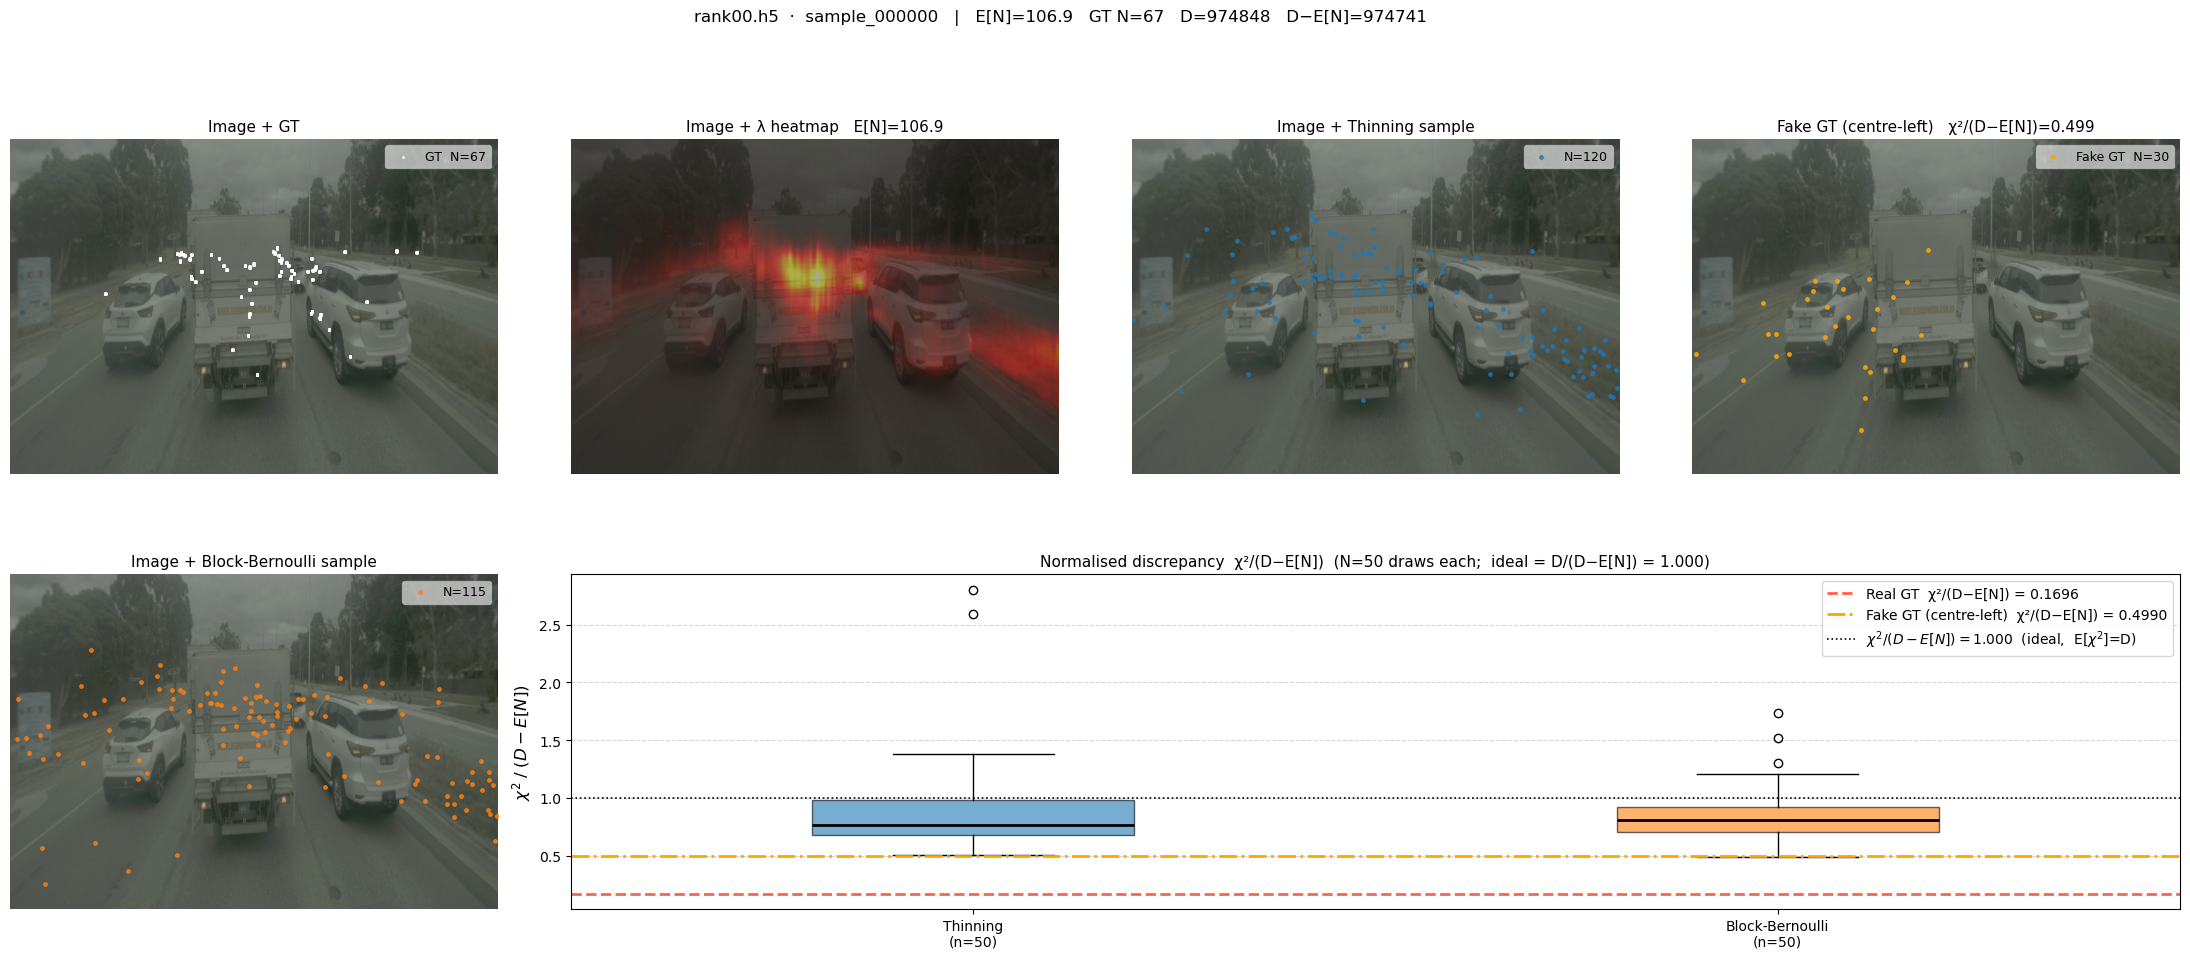

In [12]:

assert selected_samples, "No samples selected – browse and add at least one above."

from matplotlib.gridspec import GridSpec

DOT_SIZE    = 12
GT_DOT_SIZE = 4
_COLORS     = plt.cm.tab10.colors
N_EVAL      = 50   # ← number of samples drawn per method for the box plot
N_FAKE      = 30   # ← number of fake GT points (bottom-left cluster)

for _idx, (_h5_file, _key) in enumerate(selected_samples):

    # ── Load sample ──────────────────────────────────────────────────────────
    _h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == _h5_file and k == _key
    )
    _s           = load_h5_sample(_h5_path, _key)
    _img         = _s["img"]
    _pred_lambda = _s["pred_lambda"]
    _gt_support  = _s["gt_support"]
    _ppp         = _s["ppp"]
    H_img, W_img = _pred_lambda.shape
    D = _pred_lambda.size
    EN = float(_pred_lambda.sum())   # E[N]

    # Normalise by (D - E[N]):  E[T/(D-E[N])] = D/(D-E[N])  under H₀
    denom = float(D) - EN
    ideal = float(D) / denom   # expected value of T/denom under H₀

    # ── Draw one representative sample per method (for display) ──────────────
    _pts_thin_disp, *_ = sample_ppp_by_thinning(_pred_lambda,
                                                 rng=np.random.default_rng(7))
    _pts_bb_disp, _bb_stats_disp = sample_points_block_bernoulli(
        _pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(7)
    )

    # ── Draw N_EVAL samples per method → collect chi²/denom distributions ────
    _chi2_gt = bernoulli_gof(_pred_lambda, _gt_support)[0] / denom

    _chi2_thin = []
    _chi2_bb   = []
    for _seed in range(N_EVAL):
        _rng = np.random.default_rng(_seed)

        _pts, *_ = sample_ppp_by_thinning(_pred_lambda, rng=_rng)
        _g = points_to_binary_grid(_pts, H_img, W_img)
        _chi2_thin.append(bernoulli_gof(_pred_lambda, _g)[0] / denom)

        _rng2 = np.random.default_rng(_seed + 10_000)
        _pts2, _ = sample_points_block_bernoulli(
            _pred_lambda, block_size=8, placement="weighted", rng=_rng2
        )
        _g2 = points_to_binary_grid(_pts2, H_img, W_img)
        _chi2_bb.append(bernoulli_gof(_pred_lambda, _g2)[0] / denom)

    # ── [First sample only] Fake "wrong" GT: N_FAKE pts as a Gaussian cluster ─
    # Placed roughly centre-left of the image where the model predicts nothing.
    _show_fake = (_idx == 0)
    if _show_fake:
        _frng    = np.random.default_rng(42)
        # Centre: 30 % from left, 55 % from top (middle of the image)
        _cx, _cy = W_img * 0.30, H_img * 0.55
        # Spread: ~15 % of each axis
        _sx, _sy = W_img * 0.15, H_img * 0.15
        _fake_xs = np.clip(_frng.normal(_cx, _sx, size=N_FAKE), 0, W_img - 1).astype(int)
        _fake_ys = np.clip(_frng.normal(_cy, _sy, size=N_FAKE), 0, H_img - 1).astype(int)
        _fake_gt_grid = points_to_binary_grid(
            np.stack([_fake_xs, _fake_ys], axis=1), H_img, W_img
        )
        _chi2_fake = bernoulli_gof(_pred_lambda, _fake_gt_grid)[0] / denom

    # ── Shared helpers ───────────────────────────────────────────────────────
    _ext    = [0, W_img, H_img, 0]
    _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)
    _gt_ys, _gt_xs = np.where(binary_dilation(_gt_support > 0, structure=_struct))

    # ── Figure layout ─────────────────────────────────────────────────────────
    if _show_fake:
        fig = plt.figure(figsize=(28, 10))
        gs  = GridSpec(2, 4, figure=fig, hspace=0.3, wspace=0.15)
        ax_gt_p    = fig.add_subplot(gs[0, 0])
        ax_lam_p   = fig.add_subplot(gs[0, 1])
        ax_thin_p  = fig.add_subplot(gs[0, 2])
        ax_fake_p  = fig.add_subplot(gs[0, 3])
        ax_bb_p    = fig.add_subplot(gs[1, 0])
        ax_box     = fig.add_subplot(gs[1, 1:])
    else:
        fig = plt.figure(figsize=(22, 10))
        gs  = GridSpec(2, 3, figure=fig, hspace=0.3, wspace=0.15)
        ax_gt_p   = fig.add_subplot(gs[0, 0])
        ax_lam_p  = fig.add_subplot(gs[0, 1])
        ax_thin_p = fig.add_subplot(gs[0, 2])
        ax_bb_p   = fig.add_subplot(gs[1, 0])
        ax_box    = fig.add_subplot(gs[1, 1:])

    # Panel 0 – Image + GT
    ax_gt_p.imshow(_img, aspect="auto", extent=_ext)
    if _gt_ys.size > 0:
        ax_gt_p.scatter(_gt_xs, _gt_ys, s=GT_DOT_SIZE, c="white",
                        linewidths=0, alpha=0.9, label=f"GT  N={_ppp['gt_count']}")
    ax_gt_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_gt_p.axis("off")
    ax_gt_p.set_title("Image + GT", fontsize=11)

    # Panel 1 – Image + λ heatmap
    ax_lam_p.imshow(_img, aspect="auto", extent=_ext)
    ax_lam_p.imshow(_pred_lambda, cmap="hot", aspect="auto", extent=_ext, alpha=0.45)
    ax_lam_p.axis("off")
    ax_lam_p.set_title(f"Image + λ heatmap   E[N]={EN:.1f}", fontsize=11)

    # Panel 2 – Image + Thinning sample
    ax_thin_p.imshow(_img, aspect="auto", extent=_ext)
    if _pts_thin_disp.shape[0] > 0:
        ax_thin_p.scatter(_pts_thin_disp[:, 0], _pts_thin_disp[:, 1],
                          s=DOT_SIZE, c=[_COLORS[0]], linewidths=0, alpha=0.85,
                          label=f"N={_pts_thin_disp.shape[0]}")
    ax_thin_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_thin_p.axis("off")
    ax_thin_p.set_title("Image + Thinning sample", fontsize=11)

    # Panel 3 – Image + Block-Bernoulli sample
    ax_bb_p.imshow(_img, aspect="auto", extent=_ext)
    if _pts_bb_disp.shape[0] > 0:
        ax_bb_p.scatter(_pts_bb_disp[:, 0], _pts_bb_disp[:, 1],
                        s=DOT_SIZE, c=[_COLORS[1]], linewidths=0, alpha=0.85,
                        label=f"N={_bb_stats_disp['num_points']}")
    ax_bb_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_bb_p.axis("off")
    ax_bb_p.set_title("Image + Block-Bernoulli sample", fontsize=11)

    # Panel 3b – Fake "wrong" GT (first sample only)
    if _show_fake:
        ax_fake_p.imshow(_img, aspect="auto", extent=_ext)
        ax_fake_p.scatter(_fake_xs, _fake_ys, s=DOT_SIZE, c="orange",
                          linewidths=0, alpha=0.9, label=f"Fake GT  N={N_FAKE}")
        ax_fake_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
        ax_fake_p.axis("off")
        ax_fake_p.set_title(f"Fake GT (centre-left)   χ²/(D−E[N])={_chi2_fake:.3f}", fontsize=11)

    # Panel 4 – Box plot of chi²/(D-E[N]) distributions
    _bp_data   = [_chi2_thin, _chi2_bb]
    _bp_labels = [f"Thinning\n(n={N_EVAL})", f"Block-Bernoulli\n(n={N_EVAL})"]
    _bp_colors = [_COLORS[0], _COLORS[1]]

    bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,
                        widths=0.4, medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bp["boxes"], _bp_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    # GT reference line
    ax_box.axhline(_chi2_gt, color="tomato", linestyle="--", linewidth=2.0,
                   label=f"Real GT  χ²/(D−E[N]) = {_chi2_gt:.4f}")

    # Fake GT reference line (first sample only)
    if _show_fake:
        ax_box.axhline(_chi2_fake, color="orange", linestyle="-.", linewidth=2.0,
                       label=f"Fake GT (centre-left)  χ²/(D−E[N]) = {_chi2_fake:.4f}")

    # ideal reference:  E[T/(D-E[N])] = D/(D-E[N]) under H₀
    ax_box.axhline(ideal, color="black", linestyle=":", linewidth=1.2,
                   label=rf"$\chi^2/(D-E[N]) = {ideal:.3f}$  (ideal,  E[$\chi^2$]=D)")

    ax_box.set_ylabel(r"$\chi^2 \;/\; (D - E[N])$", fontsize=12)
    ax_box.set_title(
        f"Normalised discrepancy  χ²/(D−E[N])  (N={N_EVAL} draws each;"
        f"  ideal = D/(D−E[N]) = {ideal:.3f})",
        fontsize=11
    )
    ax_box.legend(fontsize=10, loc="upper right")
    ax_box.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax_box.set_axisbelow(True)

    plt.suptitle(
        f"{_h5_file}  ·  {_key}"
        f"   |   E[N]={EN:.1f}   GT N={_ppp['gt_count']}   D={D}   D−E[N]={denom:.0f}",
        fontsize=12, y=1.01,
    )
    plt.show()


## Option A — Full-Dataset Calibration Analysis (all samples, empirical null)

Runs over **every** sample. Thinning draws serve as the per-sample null reference — no iid-pixel or $\sqrt{2/D}$ assumption needed.

**Per sample $s$**, compute $K=50$ thinning draws to get empirical null parameters:

$$\mu_s = \frac{1}{K}\sum_k r_{s,k}, \quad \sigma_s = \text{std}(r_{s,k}), \quad r_{s,k} = \frac{\chi^2_{s,k}}{D_s}$$

Then standardise each method against this null:

$$z_s^\text{(GT)} = \frac{r_s^\text{GT} - \mu_s}{\sigma_s} \sim t_{K-1} \approx \mathcal{N}(0,1)$$
$$z_s^\text{(BB)} = \frac{\bar{r}_s^\text{BB} - \mu_s}{\sigma_s} \quad \text{tests BB vs thinning}$$
$$z_s^\text{(thin, LOO)} \approx 0 \quad \text{self-check: should be noise}$$

Two tests on the $S$-vector of z-scores:

| Test | Null | Catches |
|---|---|---|
| **Bias** — one-sample $t$ on $\bar{z}_s$ | $\bar{z}_s = 0$ | Systematic over / under-prediction |
| **Dispersion** — $\sum_s z_s^2 \sim \chi^2_S$ | $\text{Var}(z_s) = 1$ | Opposite-sign cancellation across images |



  Model: test_gen_data_meric_13600264  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Pooled ratio  (Bernoulli GoF statistic)
  Method                           R          SE    z_pool
  --------------------------------------------------------
  GT (real data)            2.653459    0.556380      2.97  ***
  Thinning sampler          1.025282    0.022674      1.12
  Block-Bernoulli           0.964483    0.012200     -2.91  ***

  Empirical-null calibration tests

  GT (real data)  (S=100)
    z_s  mean=+2.151  SD=11.345  min=-7.47  max=+92.25
    Bias test       t=+1.89  p=0.062
    Dispersion test Σz²=13332.9 (df=100)  p=<1e-300  ***

  Thinning (LOO)  (S=100)
    z_s  mean=+0.177  SD=0.518  min=-0.00  max=+3.87
    Bias test       t=+3.39  p=0.001  ***
    Dispersion test Σz²=30.0 (df=100)  p=1.00e+00

  Block-Bernoulli  (S=100)
    z_s  mean=+0.057  SD=0.541  min=-0.49  max=+4.37
    Bias test       t=+1.05  p

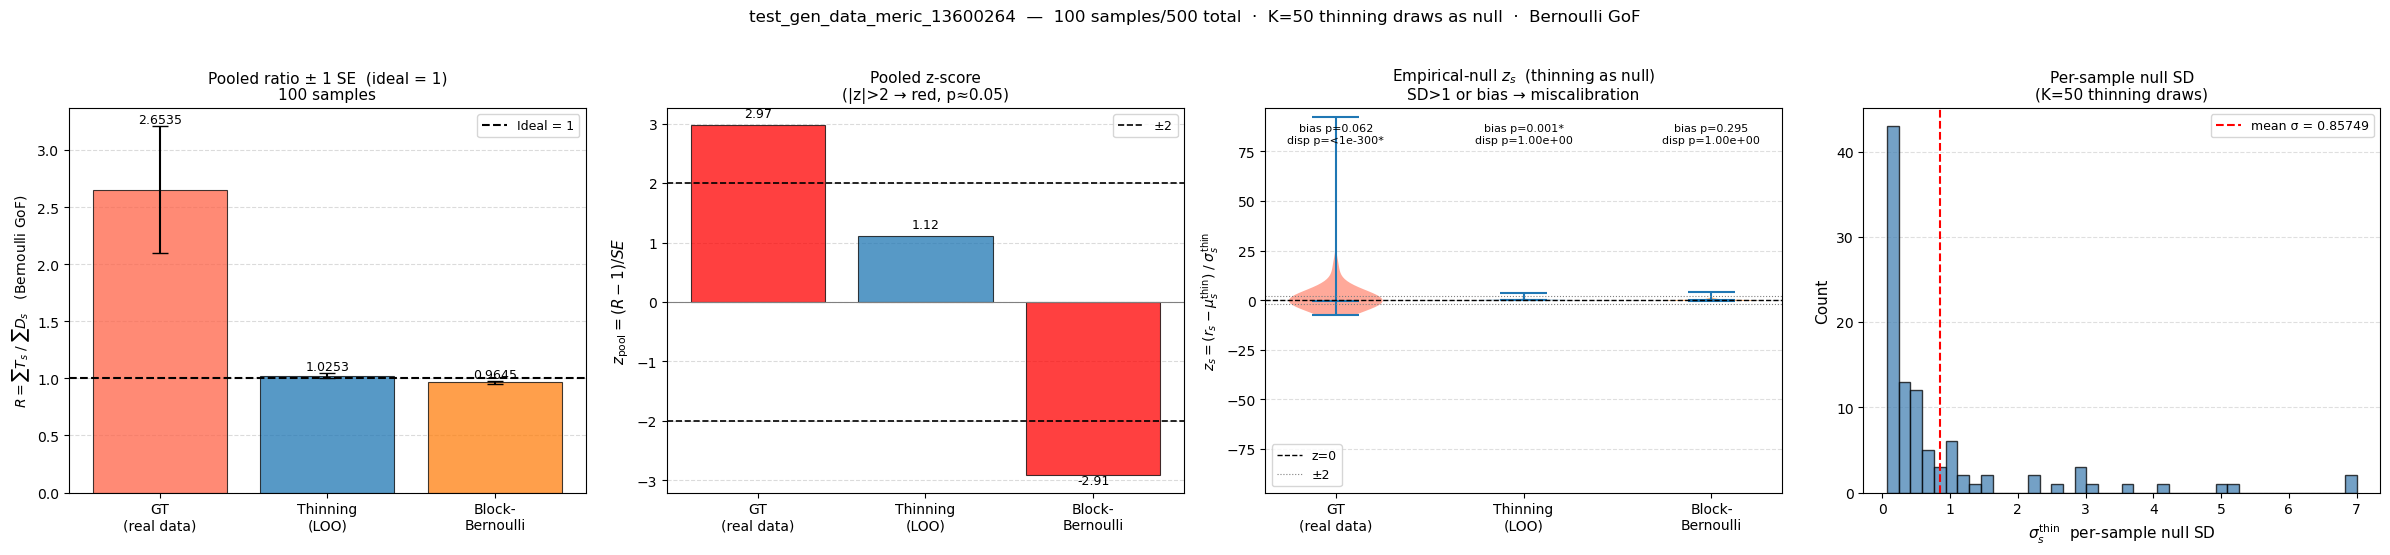

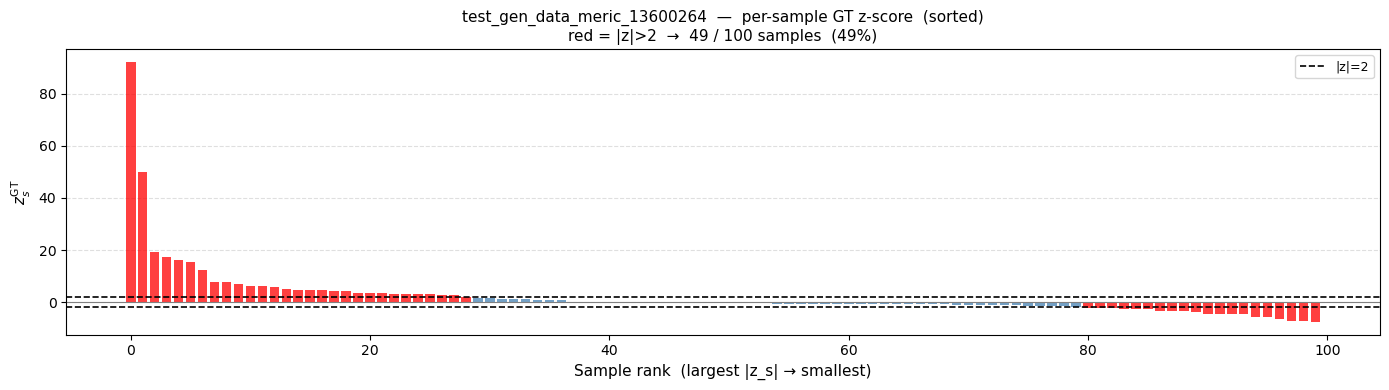


  Model: test_gen_data_meric_1500_13603608  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Pooled ratio  (Bernoulli GoF statistic)
  Method                           R          SE    z_pool
  --------------------------------------------------------
  GT (real data)            7.514891    0.732270      8.90  ***
  Thinning sampler          1.004624    0.005490      0.84
  Block-Bernoulli           0.984397    0.004200     -3.71  ***

  Empirical-null calibration tests

  GT (real data)  (S=100)
    z_s  mean=+20.643  SD=24.045  min=-1.92  max=+90.25
    Bias test       t=+8.54  p=1.63e-13  ***
    Dispersion test Σz²=100428.2 (df=100)  p=<1e-300  ***

  Thinning (LOO)  (S=100)
    z_s  mean=+0.008  SD=0.006  min=-0.00  max=+0.02
    Bias test       t=+13.43  p=4.93e-24  ***
    Dispersion test Σz²=0.0 (df=100)  p=>1-1e-15

  Block-Bernoulli  (S=100)
    z_s  mean=-0.067  SD=0.164  min=-0.44  max=+0.45
    Bias tes

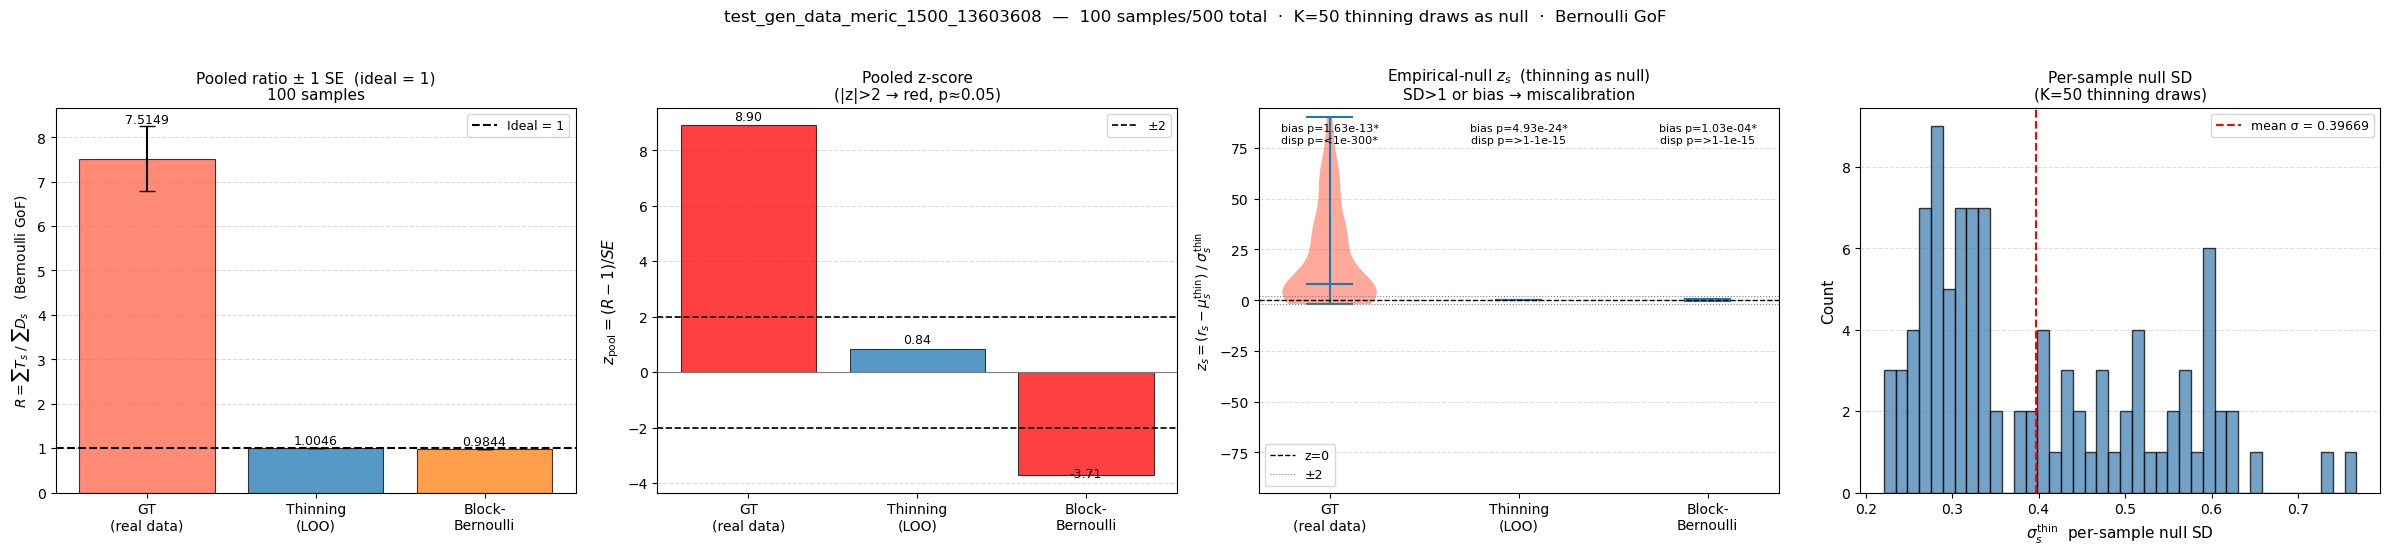

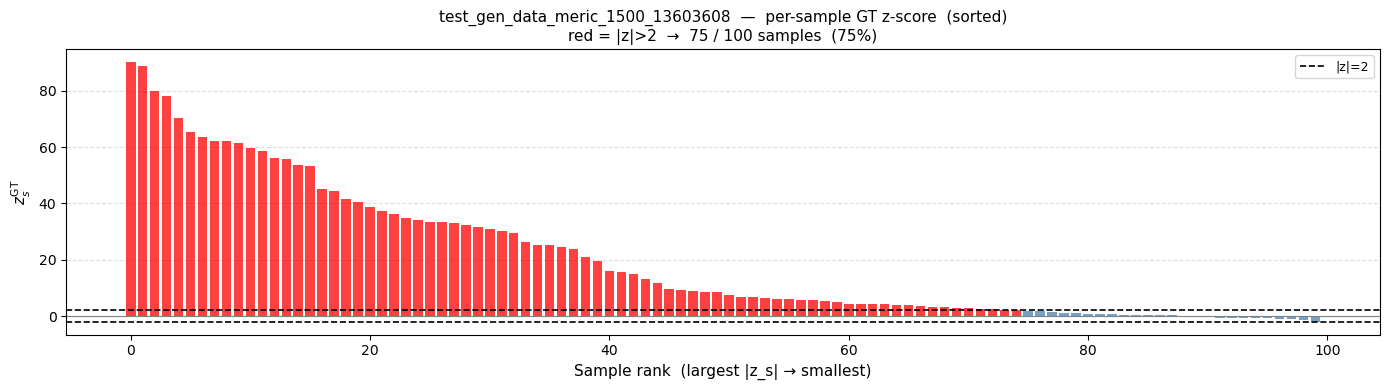

In [ ]:
N_EVAL_POOLED  = 50    # thinning / BB draws per sample  (K)
N_SAMPLES_EVAL = 100   # samples per model  (None = all)


def run_calibration_analysis(model_name: str, h5_dir: str):
    """
    Full empirical-null calibration analysis for one model.
    Statistic: Bernoulli GoF  T = Σ (x-p)²/(p(1-p)),  p = 1-exp(-λ).
    Normalised by (D - E[N]) per sample;  E[T/(D-E[N])] = D/(D-E[N]) under H₀.
    """
    # ── Collect samples ───────────────────────────────────────────────────────
    _h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    assert _h5_files, f"No rank*.h5 files found in {h5_dir}"
    _all = list_h5_samples(_h5_files)
    _eval = _all if N_SAMPLES_EVAL is None else _all[:N_SAMPLES_EVAL]
    total = len(_eval)
    print(f"\n{'='*70}")
    print(f"  Model: {model_name}  ({total} samples, K={N_EVAL_POOLED} draws)")
    print(f"{'='*70}")

    # ── Collect per-sample statistics ─────────────────────────────────────────
    gof_gt_list     = []   # (T_s, denom_s)  denom_s = D_s - E[N]_s
    mc_pval_list    = []   # always nan (no MC step for bernoulli_gof)
    thin_draws_list = []   # K draws of T/denom_s
    bb_draws_list   = []

    for idx, (_h5_path, _key) in enumerate(_eval):
        if (idx + 1) % max(1, total // 10) == 0 or idx == total - 1:
            print(f"  {idx + 1}/{total}", flush=True)

        _s           = load_h5_sample(_h5_path, _key)
        _pred_lambda = _s["pred_lambda"]
        _gt_support  = _s["gt_support"]
        H_s, W_s     = _pred_lambda.shape
        D_s          = H_s * W_s
        EN_s         = float(_pred_lambda.sum())
        denom_s      = float(D_s) - EN_s   # E[T/denom_s] = D_s/denom_s under H₀

        # GT: Bernoulli GoF
        T_gt, _ = bernoulli_gof(_pred_lambda, _gt_support)
        gof_gt_list.append((T_gt, denom_s))
        mc_pval_list.append(np.nan)

        # K thinning + BB draws
        thin_r = np.empty(N_EVAL_POOLED)
        bb_r   = np.empty(N_EVAL_POOLED)
        for seed in range(N_EVAL_POOLED):
            rng_t = np.random.default_rng(seed)
            pts_t, *_ = sample_ppp_by_thinning(_pred_lambda, rng=rng_t)
            g_t = points_to_binary_grid(pts_t, H_s, W_s)
            thin_r[seed] = bernoulli_gof(_pred_lambda, g_t)[0] / denom_s

            rng_b = np.random.default_rng(seed + 10_000)
            pts_b, _ = sample_points_block_bernoulli(
                _pred_lambda, block_size=8, placement="weighted", rng=rng_b
            )
            g_b = points_to_binary_grid(pts_b, H_s, W_s)
            bb_r[seed] = bernoulli_gof(_pred_lambda, g_b)[0] / denom_s

        thin_draws_list.append(thin_r)
        bb_draws_list.append(bb_r)

    # ── Pooled ratio + delta-method SE ────────────────────────────────────────
    S     = total
    y_gt  = np.array([y for y, _ in gof_gt_list])
    x_all = np.array([x for _, x in gof_gt_list], dtype=np.float64)  # denom_s per sample

    y_thin_gof = np.array([d.mean() * x for d, x in zip(thin_draws_list, x_all)])
    y_bb_gof   = np.array([d.mean() * x for d, x in zip(bb_draws_list,   x_all)])

    R_gt,   SE_gt,   z_pool_gt   = ratio_and_se(y_gt,       x_all)
    R_thin, SE_thin, z_pool_thin = ratio_and_se(y_thin_gof, x_all)
    R_bb,   SE_bb,   z_pool_bb   = ratio_and_se(y_bb_gof,   x_all)

    # ── Empirical-null z-scores ───────────────────────────────────────────────
    r_gt_s = y_gt / x_all
    z_gt_s, z_thin_s, z_bb_s, sigma_s = empirical_null_zscores(
        r_gt_s, thin_draws_list, bb_draws_list
    )

    # ── Print tables ──────────────────────────────────────────────────────────
    print(f"\n  Pooled ratio  (Bernoulli GoF / (D−E[N])  statistic)")
    print(f"  {'Method':<22}  {'R':>10}  {'SE':>10}  {'z_pool':>8}")
    print(f"  {'-'*56}")
    for nm, R, SE, zp in [
        ("GT (real data)",   R_gt,   SE_gt,   z_pool_gt),
        ("Thinning sampler", R_thin, SE_thin, z_pool_thin),
        ("Block-Bernoulli",  R_bb,   SE_bb,   z_pool_bb),
    ]:
        sig = "  ***" if abs(zp) > 2 else ""
        print(f"  {nm:<22}  {R:>10.6f}  {SE:>10.6f}  {zp:>8.2f}{sig}")

    mc_pvals = np.array(mc_pval_list)

    print(f"\n  Empirical-null calibration tests")
    cal_results = {}
    for nm, z_s in [("GT (real data)",  z_gt_s),
                    ("Thinning (LOO)",  z_thin_s),
                    ("Block-Bernoulli", z_bb_s)]:
        cal_results[nm] = calibration_tests(z_s, nm, verbose=True)
    print("  *** p < 0.05")

    # ── Model comparison summary ──────────────────────────────────────────────
    print(f"\n  Per-sample z_s summary  (lower mean z²  →  better calibrated)")
    print(f"  {'Method':<22}  {'mean |z|':>9}  {'mean z²':>9}  {'SD z':>7}  {'max |z|':>8}")
    print(f"  {'-'*62}")
    for nm, z_s in [("GT (real data)",  z_gt_s),
                    ("Thinning (LOO)",  z_thin_s),
                    ("Block-Bernoulli", z_bb_s)]:
        z = z_s[np.isfinite(z_s)]
        msz = np.dot(z, z) / len(z)
        print(f"  {nm:<22}  {np.abs(z).mean():>9.3f}  {msz:>9.3f}  "
              f"{z.std():>7.3f}  {np.abs(z).max():>8.2f}")

    # ── Figure (4 panels) ─────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 4, figsize=(24, 5.4))
    ax_raw, ax_zp, ax_violin, ax_sigma = axes
    base_colors = ["tomato", plt.cm.tab10.colors[0], plt.cm.tab10.colors[1]]
    labels      = ["GT\n(real data)", "Thinning\n(LOO)", "Block-\nBernoulli"]

    # Panel 1 — pooled ratio ± 1 SE
    Rs  = [R_gt,   R_thin,   R_bb]
    ses = [SE_gt,  SE_thin,  SE_bb]
    bars = ax_raw.bar(labels, Rs, color=base_colors, alpha=0.75,
                      edgecolor="k", linewidth=0.8, yerr=ses, capsize=6,
                      error_kw=dict(ecolor="black", elinewidth=1.5))
    ax_raw.axhline(1.0, color="black", linestyle="--", linewidth=1.5, label="Ideal = 1")
    for b, v, s in zip(bars, Rs, ses):
        ax_raw.text(b.get_x() + b.get_width() / 2,
                    b.get_height() + s + 0.002, f"{v:.4f}",
                    ha="center", va="bottom", fontsize=9)
    ax_raw.set_ylabel(r"$R = \sum T_s \;/\; \sum (D_s - E[N]_s)$   (Bernoulli GoF)", fontsize=10)
    ax_raw.set_title(f"Pooled ratio ± 1 SE  (ideal = 1)\n{S} samples", fontsize=11)
    ax_raw.legend(fontsize=9)
    ax_raw.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_raw.set_axisbelow(True)

    # Panel 2 — pooled z-score
    zps       = [z_pool_gt, z_pool_thin, z_pool_bb]
    zp_colors = ["red" if abs(z) > 2 else c for z, c in zip(zps, base_colors)]
    bars2 = ax_zp.bar(labels, zps, color=zp_colors, alpha=0.75,
                       edgecolor="k", linewidth=0.8)
    ax_zp.axhline( 2.0, color="black", linestyle="--", linewidth=1.2, label=r"$\pm2$")
    ax_zp.axhline(-2.0, color="black", linestyle="--", linewidth=1.2)
    ax_zp.axhline( 0.0, color="grey",  linestyle="-",  linewidth=0.8)
    for b, v in zip(bars2, zps):
        off = 0.08 if v >= 0 else -0.20
        ax_zp.text(b.get_x() + b.get_width() / 2,
                   b.get_height() + off, f"{v:.2f}",
                   ha="center", va="bottom", fontsize=9)
    ax_zp.set_ylabel(r"$z_\mathrm{pool} = (R-1)/SE$", fontsize=11)
    ax_zp.set_title("Pooled z-score\n(|z|>2 → red, p≈0.05)", fontsize=11)
    ax_zp.legend(fontsize=9)
    ax_zp.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_zp.set_axisbelow(True)

    # Panel 3 — violin of empirical-null z_s
    z_arrays = [z_gt_s[np.isfinite(z_gt_s)],
                z_thin_s[np.isfinite(z_thin_s)],
                z_bb_s[np.isfinite(z_bb_s)]]
    vp = ax_violin.violinplot(z_arrays, positions=[1, 2, 3],
                              showmedians=True, showextrema=True)
    for body, c in zip(vp["bodies"], base_colors):
        body.set_facecolor(c); body.set_alpha(0.55)
    ax_violin.axhline( 0, color="black", linewidth=1.0, linestyle="--", label="z=0")
    ax_violin.axhline( 2, color="grey",  linewidth=0.8, linestyle=":", label="±2")
    ax_violin.axhline(-2, color="grey",  linewidth=0.8, linestyle=":")
    ax_violin.set_xticks([1, 2, 3])
    ax_violin.set_xticklabels(labels)
    ax_violin.set_ylabel(
        r"$z_s = (r_s - \mu_s^\mathrm{thin})\;/\;\sigma_s^\mathrm{thin}$", fontsize=10)
    _ymax = max(np.nanmax(np.abs(z_gt_s)), np.nanmax(np.abs(z_thin_s)),
                np.nanmax(np.abs(z_bb_s)), 3.0) * 1.05
    ax_violin.set_ylim(-_ymax, _ymax)
    for pos, nm in zip([1, 2, 3],
                       ["GT (real data)", "Thinning (LOO)", "Block-Bernoulli"]):
        rr = cal_results[nm]
        ax_violin.text(pos, _ymax * 0.92,
                       f"bias p={_fmt_p(rr['p_bias'])}{'*' if rr['p_bias'] < 0.05 else ''}\n"
                       f"disp p={_fmt_p(rr['p_disp'])}{'*' if rr['p_disp'] < 0.05 else ''}",
                       ha="center", va="top", fontsize=8)
    ax_violin.set_title(
        r"Empirical-null $z_s$  (thinning as null)"
        "\nSD>1 or bias → miscalibration", fontsize=11)
    ax_violin.legend(fontsize=9)
    ax_violin.yaxis.grid(True, linestyle="--", alpha=0.4)
    ax_violin.set_axisbelow(True)

    # Panel 4 — σ_s histogram
    ax_sigma.hist(sigma_s[np.isfinite(sigma_s)], bins=40,
                  color="steelblue", alpha=0.75, edgecolor="k")
    _mean_sig = np.nanmean(sigma_s)
    ax_sigma.axvline(_mean_sig, color="red", linestyle="--",
                     label=f"mean σ = {_mean_sig:.5f}")
    ax_sigma.set_xlabel(r"$\sigma_s^\mathrm{thin}$  per-sample null SD", fontsize=11)
    ax_sigma.set_ylabel("Count", fontsize=11)
    ax_sigma.set_title(
        f"Per-sample null SD\n(K={N_EVAL_POOLED} thinning draws)", fontsize=11)
    ax_sigma.legend(fontsize=9)
    ax_sigma.yaxis.grid(True, linestyle="--", alpha=0.4)
    ax_sigma.set_axisbelow(True)

    plt.suptitle(
        f"{model_name}  —  {S} samples"
        f"{'/' + str(len(_all)) + ' total' if N_SAMPLES_EVAL is not None else ''}  ·  "
        f"K={N_EVAL_POOLED} thinning draws  ·  Bernoulli GoF / (D−E[N])",
        fontsize=12, y=1.02,
    )
    plt.tight_layout()

    # ── Figure 2: sorted GT z_s ───────────────────────────────────────────────
    _z_gt_finite  = z_gt_s[np.isfinite(z_gt_s)]
    _mc_finite    = mc_pvals[np.isfinite(z_gt_s)]
    _idx_sorted   = np.argsort(_z_gt_finite)[::-1]
    _z_sorted     = _z_gt_finite[_idx_sorted]
    _mc_sorted    = _mc_finite[_idx_sorted]
    _bar_colors   = ["red" if abs(z) > 2 else "steelblue" for z in _z_sorted]

    _has_mc = np.any(np.isfinite(_mc_sorted))

    if _has_mc:
        fig2, (ax_sorted, ax_pv) = plt.subplots(
            2, 1, figsize=(14, 7), sharex=True,
            gridspec_kw={"height_ratios": [3, 1.4], "hspace": 0.08},
        )
    else:
        fig2, ax_sorted = plt.subplots(figsize=(14, 4))

    _n_sig = int((np.abs(_z_gt_finite) > 2).sum())
    ax_sorted.bar(range(len(_z_sorted)), _z_sorted,
                  color=_bar_colors, alpha=0.75, edgecolor="none")
    ax_sorted.axhline( 2, color="black", linestyle="--", linewidth=1.2, label="|z|=2")
    ax_sorted.axhline(-2, color="black", linestyle="--", linewidth=1.2)
    ax_sorted.axhline( 0, color="grey",  linestyle="-",  linewidth=0.8)
    ax_sorted.set_ylabel(r"$z_s^\mathrm{GT}$", fontsize=11)
    ax_sorted.set_title(
        f"{model_name}  —  per-sample GT z-score  (sorted)\n"
        f"red = |z|>2  →  {_n_sig} / {len(_z_gt_finite)} samples "
        f"({100*_n_sig/max(len(_z_gt_finite),1):.0f}%)",
        fontsize=11,
    )
    ax_sorted.legend(fontsize=9)
    ax_sorted.yaxis.grid(True, linestyle="--", alpha=0.4)
    ax_sorted.set_axisbelow(True)

    if _has_mc:
        _n_mc_sig = int(np.sum(_mc_sorted < 0.05))
        _pv_colors = ["red" if p < 0.05 else "steelblue" for p in _mc_sorted]
        ax_pv.bar(range(len(_mc_sorted)), _mc_sorted,
                  color=_pv_colors, alpha=0.75, edgecolor="none")
        ax_pv.axhline(0.05, color="black", linestyle="--", linewidth=1.2,
                      label="p=0.05")
        ax_pv.set_ylim(0, 1.05)
        ax_pv.set_ylabel("MC p-value", fontsize=10)
        ax_pv.set_xlabel("Sample rank  (largest |z_s| → smallest)", fontsize=11)
        ax_pv.set_title(
            f"MC p-value  —  {_n_mc_sig}/{len(_mc_sorted)} significant (p<0.05)",
            fontsize=10,
        )
        ax_pv.legend(fontsize=9)
        ax_pv.yaxis.grid(True, linestyle="--", alpha=0.4)
        ax_pv.set_axisbelow(True)
    else:
        ax_sorted.set_xlabel("Sample rank  (largest |z_s| → smallest)", fontsize=11)

    plt.tight_layout()
    return fig, fig2


# ── Run for every registered model ────────────────────────────────────────────
for _model_name, _h5_dir in H5_DIRS.items():
    if not os.path.isdir(_h5_dir):
        print(f"SKIPPING {_model_name} — directory not found: {_h5_dir}")
        continue
    _fig, _fig2 = run_calibration_analysis(_model_name, _h5_dir)
    plt.show()
